# Document preprocessing for OCR

This notebook builds a deterministic preprocessing workflow for a randomly selected image under `data/images`. It keeps the original image untouched and produces two OCR candidates: normalized grayscale and adaptive binary.

The workflow is intentionally Python/OpenCV based. All four corrections (0/90/180/270 degrees counterclockwise) are supported. When PaddleOCR is installed it resolves all four automatically; otherwise the notebook removes long page/table rules, identifies the text axis, and records the unresolved 0/180 or 90/270 pair instead of treating either direction as impossible.

Run this notebook with the project environment (`uv sync` then select `.venv`) or rebuild `docker/jupyter` with `docker compose -f docker/jupyter/compose.yaml up --build`.

In [1]:
from pathlib import Path
import random

PACKAGE_DIR = Path('/home/jovyan/ocr')
if not PACKAGE_DIR.exists():
    PACKAGE_DIR = Path('../ocr').resolve()
%pip install --no-deps --no-build-isolation -e {PACKAGE_DIR}


Obtaining file:///C:/Users/vmjua/Documents/GitHub/ocr-invoice/ocr
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for ocr-extraction (pyproject.toml): started
  Building editable for ocr-extraction (pyproject.toml): finished with status 'done'
  Created wheel for ocr-extraction: filename=ocr_extraction-0.1.0-0.editable-py3-none-any.whl size=1651 sha256=9cd01790c882e179d531ca4857c855a54aaf8fcf544fee1401281d25fa9ee6d4
  Stored in directory: C:\Users\vmjua\AppData\Local\Temp\pip-ephem-wheel-cache-4vj7cd47\wheels\0b\54\0f\5c6684204c9cf04874a27b8ad6015fdef0c14a629b1d8778ed
Successfully built ocr-extraction
  Attempting uninstall: ocr-extraction
    Found existing installation: ocr-extraction 0.1.0
    Uninstalling ocr-extraction-0.1.0:
      Success

In [2]:
SEED = 42
IMAGE_DIR = Path('../data/images')
RUN_DIR = Path('../runs/preprocessing')
EXPLICIT_IMAGE: Path | None = None

image_paths = sorted(p for p in IMAGE_DIR.glob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.webp'})
if not image_paths:
    raise FileNotFoundError(f'No supported images found in {IMAGE_DIR.resolve()}')
rng = random.Random(SEED)
input_path = EXPLICIT_IMAGE or rng.choice(image_paths)
print(f'Selected: {input_path} ({len(image_paths)} images available)')


Selected: ..\data\images\albaran-3.jpeg (3 images available)


## Package API

The reusable implementation lives in `ocr/src/ocr_extraction`. This notebook installs that mounted source in editable mode and only contains experiment orchestration and visualization.

In [3]:
import json

import cv2
import matplotlib.pyplot as plt

from ocr_extraction import PreprocessResult, preprocess_document, save_result


In [4]:
# The preprocessing implementation is imported from the editable package above.


{
  "width": 1080,
  "height": 1920,
  "mode": "RGB",
  "exif_orientation": null,
  "orientation_angle": 90,
  "orientation_candidates": [
    90,
    270
  ],
  "orientation_score": 1.2834842641778414,
  "orientation_method": "text-axis-fallback-ambiguous (ModuleNotFoundError)",
  "deskew_angle": 0.0,
  "elapsed_seconds": 0.18482740000035847,
  "page_detected": false,
  "page_score": null
}
warnings: ['No confident page quadrilateral found; using the full image.']


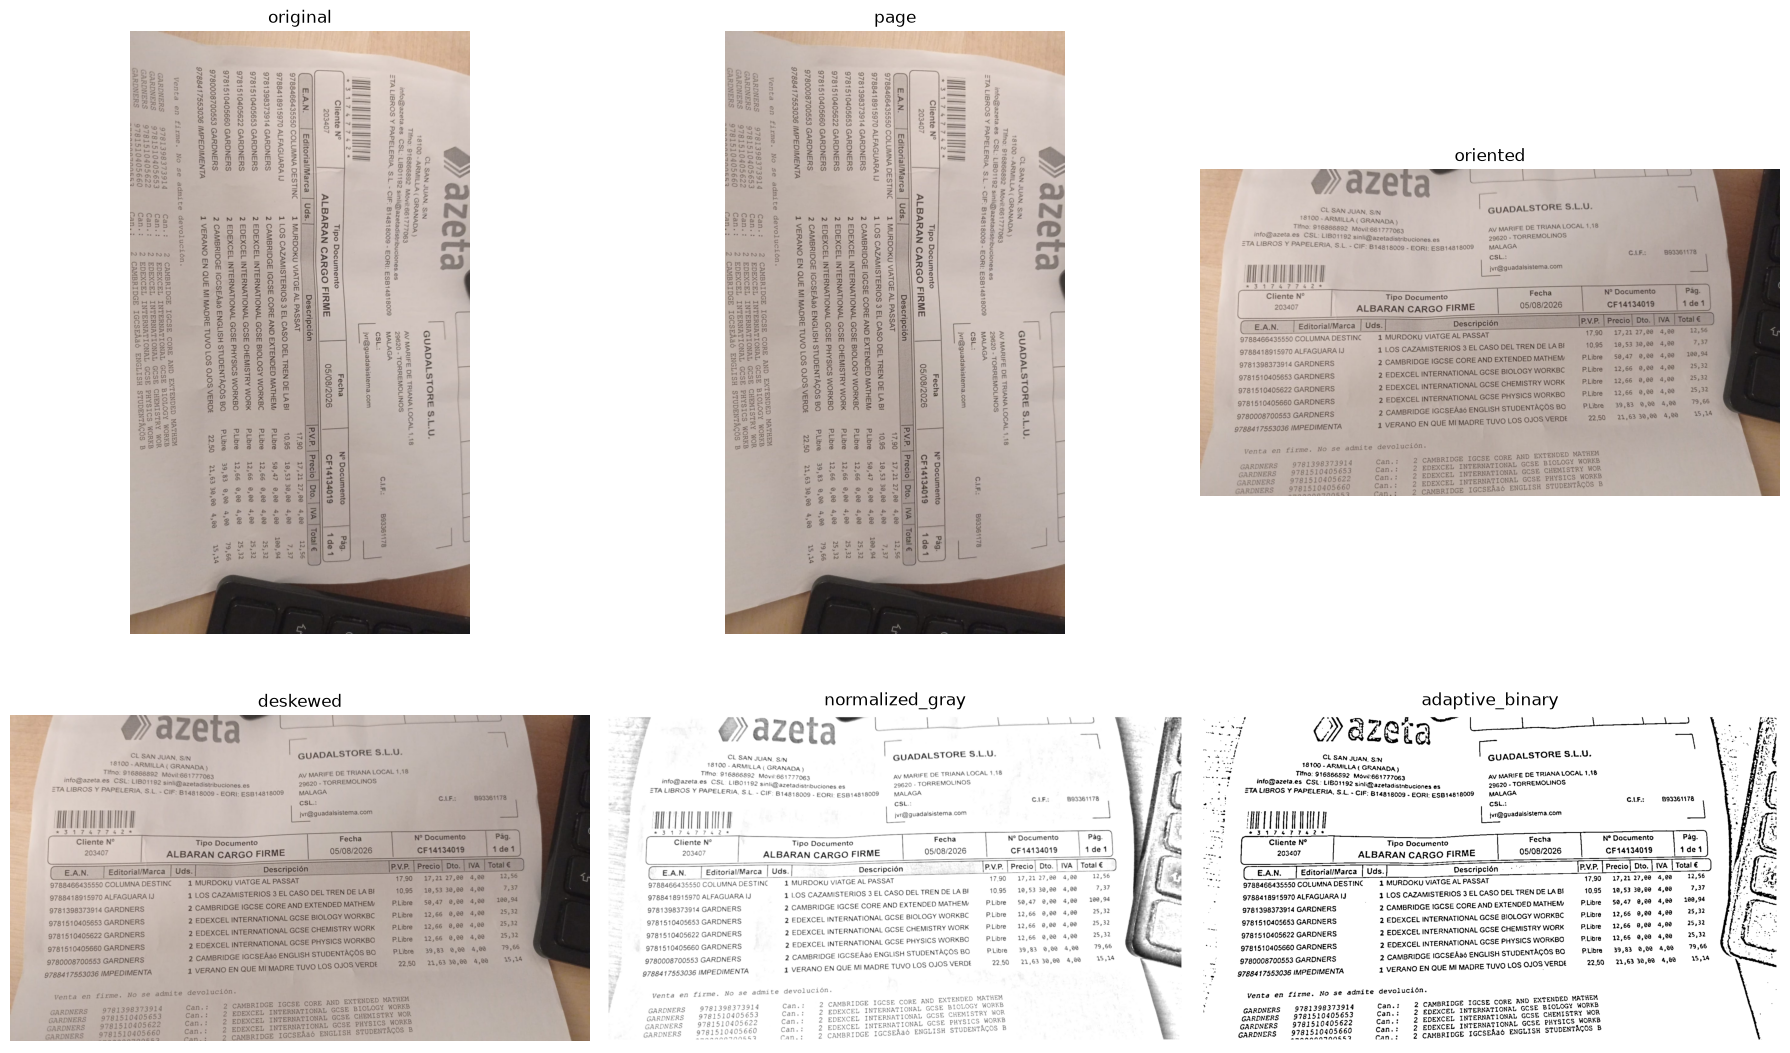

In [5]:
result = preprocess_document(input_path)
print(json.dumps({k: v for k, v in result.metadata.items() if k != 'corners'}, indent=2))
print('warnings:', result.warnings)

def show_stage_gallery(result: PreprocessResult) -> None:
    names = ['original', 'page', 'oriented', 'deskewed', 'normalized_gray', 'adaptive_binary']
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    for axis, name in zip(axes.flat, names):
        image = result.stages[name]
        if image.ndim == 3:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        axis.imshow(image, cmap='gray')
        axis.set_title(name)
        axis.axis('off')
    plt.tight_layout()

show_stage_gallery(result)


In [6]:
save_result(result, RUN_DIR)


WindowsPath('../runs/preprocessing/albaran-3')

## Batch check

The batch run is diagnostic rather than a claim of OCR accuracy. Review the generated galleries and metadata, especially when page detection is low-confidence or the optional orientation model is unavailable.

In [7]:
batch = []
for path in image_paths:
    item = preprocess_document(path)
    output_dir = save_result(item, RUN_DIR)
    batch.append({'image': path.name, 'output': str(output_dir), **{k: item.metadata[k] for k in ('orientation_angle', 'orientation_candidates', 'orientation_score', 'orientation_method', 'deskew_angle', 'page_detected', 'page_score')}, 'warnings': item.warnings})

print(json.dumps(batch, indent=2))


[
  {
    "image": "albaran-1.jpeg",
    "output": "..\\runs\\preprocessing\\albaran-1",
    "orientation_angle": 90,
    "orientation_candidates": [
      90,
      270
    ],
    "orientation_score": 8.913916358016184,
    "orientation_method": "text-axis-fallback-ambiguous (ModuleNotFoundError)",
    "deskew_angle": 2.7191314697265625,
    "page_detected": false,
    "page_score": null,
    "warnings": [
      "No confident page quadrilateral found; using the full image."
    ]
  },
  {
    "image": "albaran-2.jpeg",
    "output": "..\\runs\\preprocessing\\albaran-2",
    "orientation_angle": 90,
    "orientation_candidates": [
      90,
      270
    ],
    "orientation_score": 7.1989547933442894,
    "orientation_method": "text-axis-fallback-ambiguous (ModuleNotFoundError)",
    "deskew_angle": 0.0,
    "page_detected": false,
    "page_score": null,
    "warnings": [
      "No confident page quadrilateral found; using the full image."
    ]
  },
  {
    "image": "albaran-3.jpeg",

### Interpretation and next steps

Use `normalized_gray.png` as the default OCR input and compare it with `adaptive_binary.png`. Add a small labelled validation set with expected orientation, page corners, and anchor text before tuning thresholds. If the camera images routinely contain curved pages or severe perspective, enable PaddleOCR's document preprocessor/unwarping model rather than increasing classical morphology.